# Medical Image Classification with Transfer Learning + Grad-CAM (XAI)

**Subject:** Deep Learning and Applications — Capstone Project
**Task:** Classify chest X-ray images (COVID-19 / Normal / Viral Pneumonia / Lung Opacity) using transfer learning (ResNet18), and use Grad-CAM to visualize *why* the model made its decision — useful for clinical verification.

**Run this notebook on Google Colab with a GPU** (Runtime → Change runtime type → T4 GPU). It will also run on CPU, just slower.

**Dataset used:** [COVID-19 Radiography Database (Kaggle)](https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database)
4 classes: `COVID`, `Normal`, `Lung_Opacity`, `Viral Pneumonia`.


## 1. Setup

In [15]:
%pip install -q torch torchvision scikit-learn matplotlib kagglehub


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Download the dataset

Uses `kagglehub` to pull the dataset directly (no manual upload needed on Colab).
If you already have the dataset locally, just set `DATA_ROOT` to that folder instead and skip this cell.


In [16]:
import kagglehub

# Downloads once, cached afterward
path = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")
print("Dataset downloaded to:", path)

# The Kaggle dataset nests images inside per-class subfolders with an 'images' folder inside each.
# We build a clean ImageFolder-compatible directory with symlinks.
import os, glob, shutil

DATA_ROOT =  "./xray_data"
CLASSES = ["COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"]

if not os.path.exists(DATA_ROOT):
    os.makedirs(DATA_ROOT, exist_ok=True)
    base = glob.glob(os.path.join(path, "COVID-19_Radiography_Dataset"))
    base = base[0] if base else path
    for cls in CLASSES:
        src_img_dir = os.path.join(base, cls, "images")
        dst_dir = os.path.join(DATA_ROOT, cls)
        os.makedirs(dst_dir, exist_ok=True)
        if os.path.isdir(src_img_dir):
            for f in os.listdir(src_img_dir):
                s = os.path.join(src_img_dir, f)
                d = os.path.join(dst_dir, f)
                if not os.path.exists(d):
                    os.symlink(s, d)

print("Classes found:", os.listdir(DATA_ROOT))


Dataset downloaded to: C:\Users\rijul\.cache\kagglehub\datasets\tawsifurrahman\covid19-radiography-database\versions\5
Classes found: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


**Tip (to keep training fast for a capstone demo):** you don't need the full dataset (~21k images).
The cell below randomly subsamples each class to `N_PER_CLASS` images so the whole notebook — including
on a modest laptop CPU — finishes in a few minutes. Increase this number if you have a GPU and want
better accuracy.


In [17]:
import random

N_PER_CLASS = 300  # lower (e.g. 100) for a very quick CPU run, raise (e.g. 1000+) on GPU

SUBSET_ROOT = "./xray_subset"
if not os.path.exists(SUBSET_ROOT):
    os.makedirs(SUBSET_ROOT, exist_ok=True)
    for cls in CLASSES:
        src_dir = os.path.join(DATA_ROOT, cls)
        dst_dir = os.path.join(SUBSET_ROOT, cls)
        os.makedirs(dst_dir, exist_ok=True)
        files = os.listdir(src_dir)
        random.seed(42)
        chosen = random.sample(files, min(N_PER_CLASS, len(files)))
        for f in chosen:
            s = os.path.join(src_dir, f)
            d = os.path.join(dst_dir, f)
            if not os.path.exists(d):
                os.symlink(os.path.realpath(s), d)

for cls in CLASSES:
    print(cls, "->", len(os.listdir(os.path.join(SUBSET_ROOT, cls))), "images")


COVID -> 300 images
Normal -> 300 images
Lung_Opacity -> 300 images
Viral Pneumonia -> 300 images


## 3. Imports & Config

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import cv2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 5          # keep small for a quick capstone run; raise for better accuracy
LR = 1e-4
NUM_CLASSES = len(CLASSES)


Using device: cpu


## 4. Data Loading & Augmentation

In [19]:
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),
])

full_dataset = datasets.ImageFolder(SUBSET_ROOT, transform=train_tfms)
class_names = full_dataset.classes
print("Class -> index mapping:", full_dataset.class_to_idx)

n_total = len(full_dataset)
n_train = int(0.7 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

train_ds, val_ds, test_ds = random_split(
    full_dataset, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42)
)
# use eval transforms (no augmentation) for val/test
val_ds.dataset.transform = eval_tfms
test_ds.dataset.transform = eval_tfms

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {n_train} | Val: {n_val} | Test: {n_test}")


Class -> index mapping: {'COVID': 0, 'Lung_Opacity': 1, 'Normal': 2, 'Viral Pneumonia': 3}
Train: 840 | Val: 180 | Test: 180


## 5. Model: Transfer Learning with ResNet18

We load ImageNet-pretrained ResNet18, freeze the early layers (they already know generic edge/texture
features), and fine-tune the last residual block + a new classification head for our 4 X-ray classes.


In [20]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze everything except the last block and the final FC layer
for name, param in model.named_parameters():
    if not (name.startswith("layer4") or name.startswith("fc")):
        param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(device)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
criterion = nn.CrossEntropyLoss()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / {total:,}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\rijul/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 11.7MB/s]


Trainable params: 8,395,780 / 11,178,564


## 6. Training Loop

In [21]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    torch.set_grad_enabled(train)
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        if train:
            optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        if train:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        n += imgs.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} "
          f"| val_loss={val_loss:.4f} val_acc={val_acc:.3f}")


Epoch 1/5 | train_loss=0.5828 train_acc=0.781 | val_loss=0.4213 val_acc=0.828
Epoch 2/5 | train_loss=0.1276 train_acc=0.970 | val_loss=0.3043 val_acc=0.883
Epoch 3/5 | train_loss=0.0528 train_acc=0.994 | val_loss=0.3265 val_acc=0.883
Epoch 4/5 | train_loss=0.0404 train_acc=0.994 | val_loss=0.3183 val_acc=0.878
Epoch 5/5 | train_loss=0.0271 train_acc=0.998 | val_loss=0.2963 val_acc=0.872


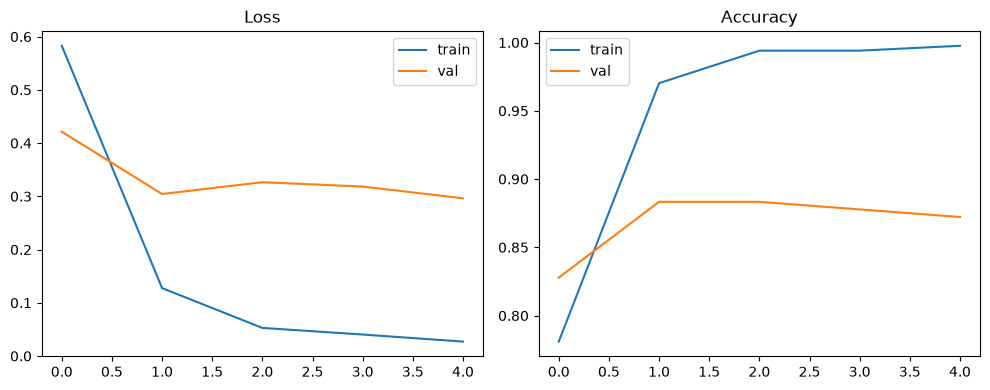

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history["train_acc"], label="train"); axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()


## 7. Evaluation on Test Set

                 precision    recall  f1-score   support

          COVID       0.97      0.82      0.89        45
   Lung_Opacity       0.84      0.89      0.87        47
         Normal       0.84      0.88      0.86        43
Viral Pneumonia       0.94      0.98      0.96        45

       accuracy                           0.89       180
      macro avg       0.90      0.89      0.89       180
   weighted avg       0.90      0.89      0.89       180



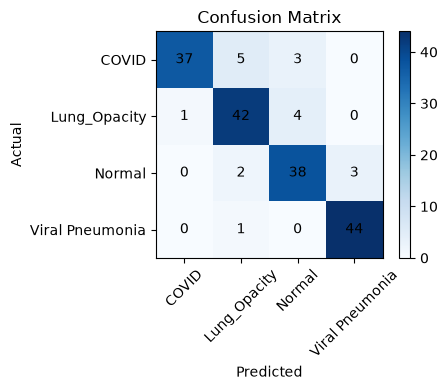

In [23]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(NUM_CLASSES), class_names, rotation=45)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(); plt.tight_layout(); plt.show()


In [26]:
torch.set_grad_enabled(True) # re-enable gradients — turned off globally by the last eval/test loop

torch.autograd.grad_mode.set_grad_enabled(mode=True)

## 8. Explainable AI: Grad-CAM

Grad-CAM highlights the image regions the model relied on most for its prediction — important for clinical
verification, since a radiologist can sanity-check whether the model is actually "looking at" the lungs
and not some irrelevant artifact.

Implemented from scratch with forward/backward hooks on the last convolutional layer (`layer4`) — no
extra library needed.


In [27]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        self.model.zero_grad()
        score = output[0, class_idx]
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)  # global avg pool of gradients
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = cam.squeeze().cpu().numpy()
        cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, output.softmax(dim=1)[0, class_idx].item()

gradcam = GradCAM(model, model.layer4[-1])


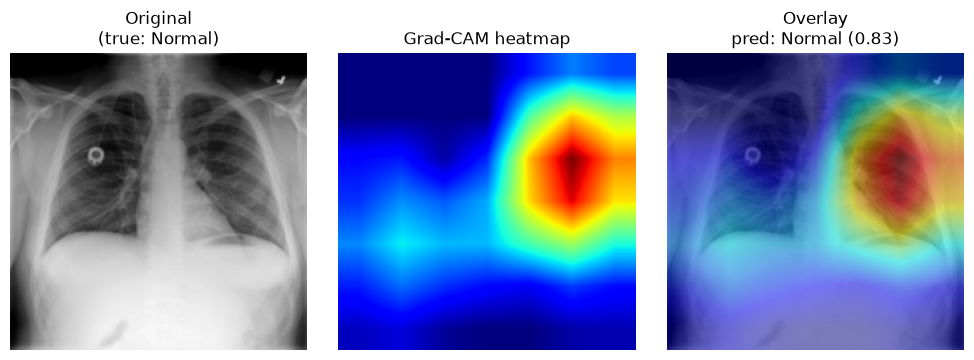

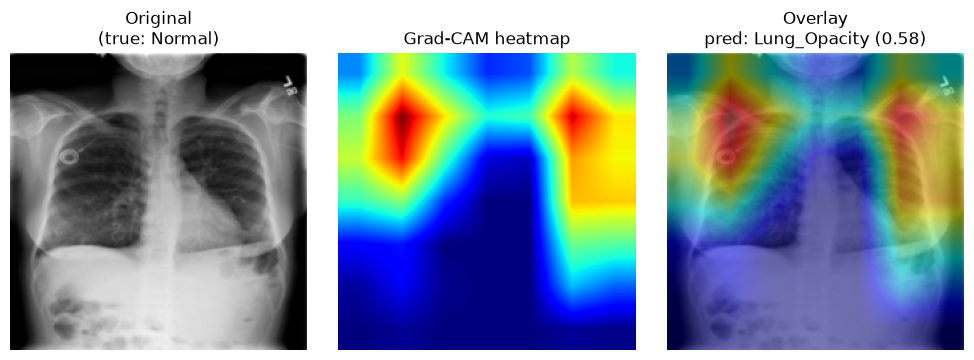

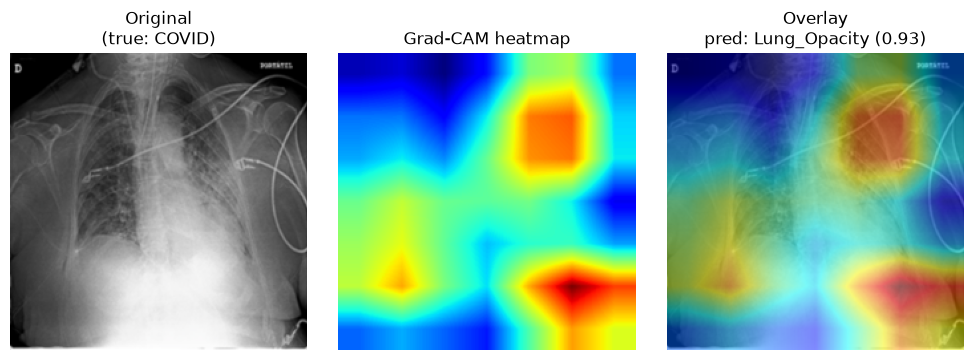

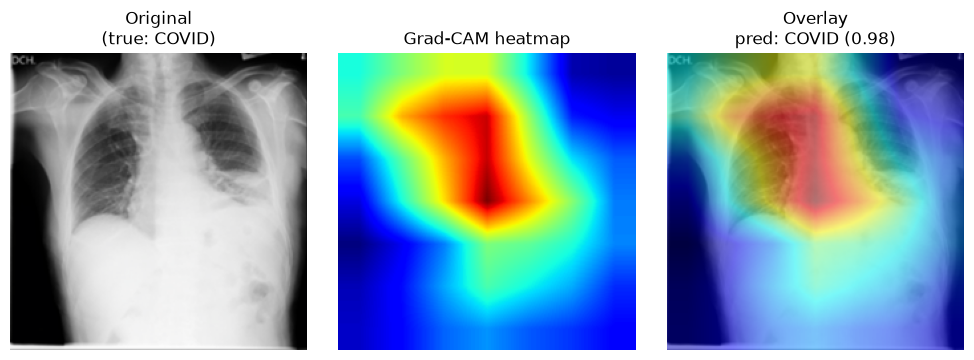

In [28]:
def unnormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img = std * img + mean
    return np.clip(img, 0, 1)

def show_gradcam(img_tensor, true_label):
    input_tensor = img_tensor.unsqueeze(0).to(device)
    cam, pred_idx, confidence = gradcam.generate(input_tensor)

    orig = unnormalize(img_tensor)
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET) / 255.0
    heatmap = heatmap[..., ::-1]  # BGR -> RGB
    overlay = 0.5 * orig + 0.5 * heatmap
    overlay = np.clip(overlay, 0, 1)

    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    axes[0].imshow(orig); axes[0].set_title(f"Original\n(true: {class_names[true_label]})"); axes[0].axis("off")
    axes[1].imshow(cam, cmap="jet"); axes[1].set_title("Grad-CAM heatmap"); axes[1].axis("off")
    axes[2].imshow(overlay); axes[2].set_title(f"Overlay\npred: {class_names[pred_idx]} ({confidence:.2f})"); axes[2].axis("off")
    plt.tight_layout(); plt.show()

# Show Grad-CAM for a handful of test images
sample_indices = np.random.choice(len(test_ds), size=4, replace=False)
for idx in sample_indices:
    img_tensor, label = test_ds[idx]
    show_gradcam(img_tensor, label)


## 9. Save the Model

In [29]:
torch.save(model.state_dict(), "resnet18_xray_classifier.pth")
print("Saved model weights to resnet18_xray_classifier.pth")


Saved model weights to resnet18_xray_classifier.pth


## 10. Conclusion

- Fine-tuned a pretrained **ResNet18** (transfer learning) to classify chest X-rays into COVID / Normal /
  Lung Opacity / Viral Pneumonia.
- Only the last residual block + classifier head were trained, keeping compute cost low — practical even
  on a laptop CPU for a quick demo, and fast on a free Colab GPU.
- Added a from-scratch **Grad-CAM** implementation to visualize which lung regions drove each prediction,
  giving a clinician-facing explanation rather than a black-box label.

**Possible extensions (not required for this capstone):** try VGG16 as a second backbone and compare
accuracy, unfreeze more layers for longer fine-tuning, or use the full dataset instead of the subsample.
